# Kalibratie, drift en meetonzekerheid van goedkope gassensoren

**Vraag.** Kunnen goedkope metaaloxide-sensoren, gekalibreerd tegen een referentie-analysator,
betrouwbare luchtkwaliteitsdata leveren? Hoe vaak moeten ze opnieuw gekalibreerd worden, en wat is
de meetonzekerheid volgens de GUM?

**Data.** [UCI Air Quality](https://archive.ics.uci.edu/dataset/360/air+quality) (De Vito et al., 2008):
9 357 uurwaarden (maart 2004 – april 2005) van een sensorarray naast een gecertificeerde referentie-analysator.
We bekijken twee kanalen:

| Sensor | Ruw signaal | Referentie | Eenheid |
|---|---|---|---|
| CO | `PT08.S1(CO)` | `CO(GT)` | mg/m³ |
| NO2 | `PT08.S4(NO2)` | `NO2(GT)` | µg/m³ |

**Acceptatiecriterium.** Data Quality Objective voor *indicatieve* metingen uit Richtlijn 2008/50/EG,
bijlage I: relatieve uitgebreide onzekerheid ≤ 25 %.

**Achtergrond.** In mijn masterthesis (NTU "KhPI", 2018, Metrologie en informatie-meettechniek) ontwierp ik
een IoT-meetsysteem (Arduino + ESP8266 + ThingSpeak) voor pH, temperatuur en opgeloste zuurstof, met een
foutenanalyse per meetkanaal. Dit project zet de volgende stap: dezelfde metrologische vragen, maar
beantwoord met echte velddata, een gevalideerd onzekerheidsbudget en een Monte Carlo-controle.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from kalibratie import *

FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# Huisstijl grafieken: rustige assen, dunne lijnen, vaste kleurvolgorde.
INKT, INKT2, RASTER, ACHTERGROND = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
BLAUW, ORANJE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.facecolor": ACHTERGROND, "axes.facecolor": ACHTERGROND,
    "axes.edgecolor": RASTER, "axes.labelcolor": INKT2, "text.color": INKT,
    "xtick.color": INKT2, "ytick.color": INKT2, "axes.grid": True,
    "grid.color": RASTER, "grid.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "font.size": 10, "lines.linewidth": 1.6,
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 160,
    "savefig.bbox": "tight", "axes.axisbelow": True,
})
pd.options.display.float_format = "{:.3f}".format

df = laad_ruwe_data()
validatie = df.index > KALIBRATIE_EINDE
df.shape, df.index.min(), df.index.max()

((9357, 13),
 Timestamp('2004-03-10 18:00:00'),
 Timestamp('2005-04-04 14:00:00'))

## 1. Datakwaliteit

In de ruwe data staat `-200` voor een ontbrekende waarde. Voor elk sensorkanaal markeren we ook
vastgelopen waarden (≥ 4 uur identiek) en pieken (robuuste z-score > 6 t.o.v. de lopende mediaan).

In [2]:
rijen = []
for s, c in SENSOREN.items():
    v = kwaliteitsvlaggen(df[c["ruw"]])
    rijen.append({"sensor": s,
                  "volledigheid sensor": 1 - v.ontbreekt.mean(),
                  "volledigheid referentie": df[c["ref"]].notna().mean(),
                  "vastgelopen (uren)": int(v.vastgelopen.sum()),
                  "pieken (uren)": int(v.piek.sum())})
pd.DataFrame(rijen).set_index("sensor")

,volledigheid sensor,volledigheid referentie,vastgelopen (uren),pieken (uren)
sensor,,,,
CO,0.961,0.820,0,1
NO2,0.961,0.825,0,5


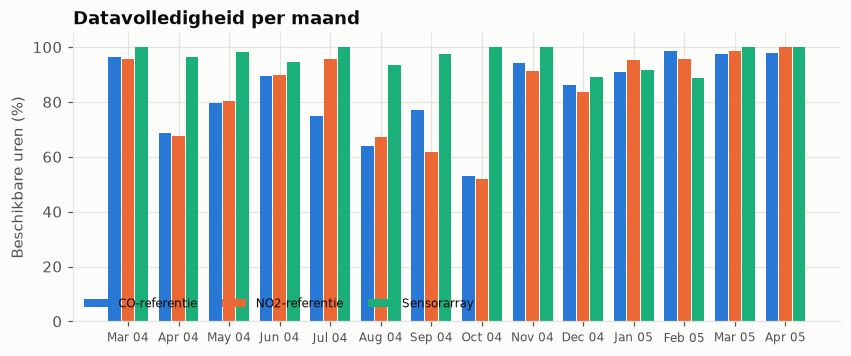

In [3]:
vol = pd.DataFrame({
    "CO-referentie": df["CO(GT)"].notna().resample("MS").mean(),
    "NO2-referentie": df["NO2(GT)"].notna().resample("MS").mean(),
    "Sensorarray": df["PT08.S1(CO)"].notna().resample("MS").mean(),
})
fig, ax = plt.subplots(figsize=(9, 3.4))
x = np.arange(len(vol))
for i, (kol, kleur) in enumerate(zip(vol.columns, [BLAUW, ORANJE, AQUA])):
    ax.bar(x + (i - 1) * 0.27, vol[kol] * 100, width=0.25, color=kleur, label=kol)
ax.set_xticks(x, vol.index.strftime("%b %y"), rotation=0, fontsize=8)
ax.set_ylabel("Beschikbare uren (%)")
ax.set_ylim(0, 105)
ax.set_title("Datavolledigheid per maand")
ax.legend(ncol=3, loc="lower left", fontsize=8)
fig.savefig(FIG / "01_datavolledigheid.png");

**Bevinding.** De sensorarray is 96 % van de tijd beschikbaar, de referentie-analysatoren maar ~82 %.
Vooral in oktober 2004 ontbreekt veel referentiedata. Juist daarom is een goed gekalibreerde sensor nuttig:
hij vult de gaten van het dure toestel op.

## 2. Kalibratiemodel

Metaaloxide-sensoren hebben een machtswet-respons, dus fitten we in log-ruimte:

$$\ln c_\text{ref} = \beta_0 + \beta_1 \ln S_\text{ruw} \;\big[+\; \beta_2 T + \beta_3 \text{AH}\big]$$

De termen tussen haakjes corrigeren voor temperatuur en absolute vochtigheid (kruisgevoeligheid).
Kalibratieperiode: 10 maart – 30 april 2004 (co-locatie van ~7 weken). Alles daarna is validatie.

In [4]:
rijen = []
for s, c in SENSOREN.items():
    for omg in (False, True):
        m = fit(df.loc[:KALIBRATIE_EINDE], c["ref"], c["ruw"], omg)
        p_kal = prestaties(df.loc[~validatie, c["ref"]], kalibreer(df, s, omg)[~validatie])
        p_val = prestaties(df.loc[validatie, c["ref"]], kalibreer(df, s, omg)[validatie])
        rijen.append({"sensor": s, "model": "+ T, AH" if omg else "alleen sensor",
                      "β1 (exponent)": m.beta[1], "s_res (ln)": m.s_res,
                      "R² kalibratie": p_kal["r2"], "R² validatie": p_val["r2"],
                      "RMSE validatie": p_val["rmse"]})
modellen = pd.DataFrame(rijen).set_index(["sensor", "model"])
modellen

β1 (exponent)  s_res (ln)  R² kalibratie  R² validatie  \
sensor model                                                                   
CO     alleen sensor          3.070       0.243          0.847         0.707   
       + T, AH                3.184       0.226          0.828         0.619   
NO2    alleen sensor          1.664       0.234          0.596        -0.656   
       + T, AH                1.908       0.210          0.648        -0.580   

                      RMSE validatie  
sensor model                          
CO     alleen sensor           0.780  
       + T, AH                 0.889  
NO2    alleen sensor          63.313  
       + T, AH                61.841

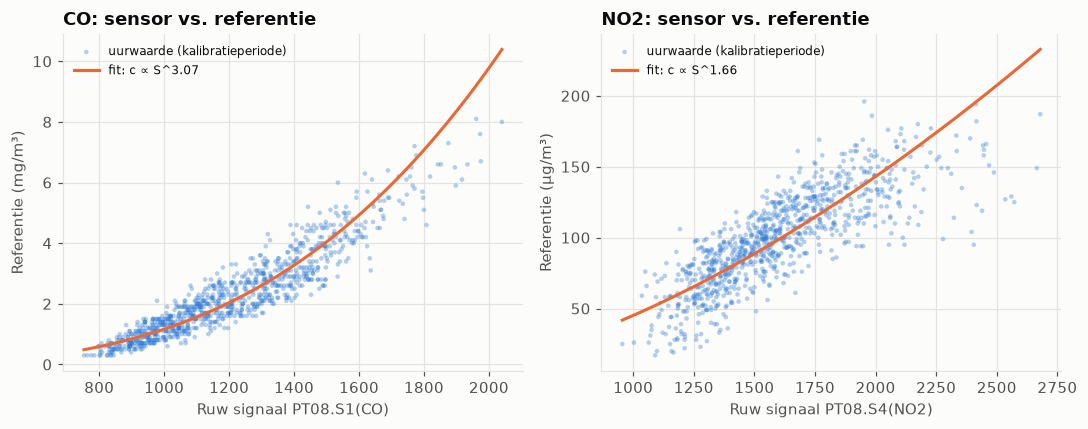

In [5]:
fig, assen = plt.subplots(1, 2, figsize=(10, 4))
for ax, (s, c) in zip(assen, SENSOREN.items()):
    d = df.loc[:KALIBRATIE_EINDE, [c["ref"], c["ruw"], "T", "AH"]].dropna()
    d = d[d[c["ref"]] > 0]
    ax.scatter(d[c["ruw"]], d[c["ref"]], s=9, color=BLAUW, alpha=0.35,
               edgecolors="none", label="uurwaarde (kalibratieperiode)")
    m = fit(df.loc[:KALIBRATIE_EINDE], c["ref"], c["ruw"], False)
    xs = np.linspace(d[c["ruw"]].min(), d[c["ruw"]].max(), 200)
    ax.plot(xs, np.exp(m.beta[0] + m.beta[1] * np.log(xs) + m.s_res**2 / 2),
            color=ORANJE, lw=2, label=f"fit: c ∝ S^{m.beta[1]:.2f}")
    ax.set_xlabel(f"Ruw signaal {c['ruw']}")
    ax.set_ylabel(f"Referentie ({c['eenheid']})")
    ax.set_title(f"{s}: sensor vs. referentie")
    ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig(FIG / "02_kalibratiecurves.png");

**Bevinding.** Een omgevingscorrectie is geen automatische verbetering:

* **CO**: met T en AH worden de residuen in de kalibratieperiode iets kleiner (s_res 0,243 → 0,226), maar de validatie wordt slechter (RMSE 0,78 → 0,89 mg/m³).
  Het model leert voorjaarscondities en extrapoleert slecht naar de zomer (overfitting).
  → we gebruiken voor CO het model *zonder* omgevingstermen.
* **NO2**: de sensor is sterk kruisgevoelig voor temperatuur en vocht (correlatie ruw signaal–AH = 0,63).
  → voor NO2 houden we de correctie.

## 3. Drift: hoe lang blijft één kalibratie geldig?

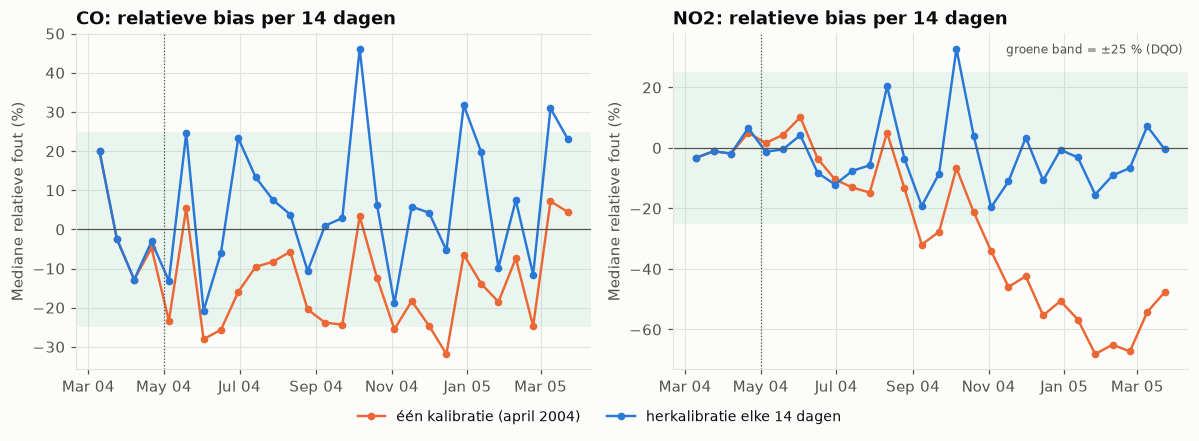

In [6]:
kal = {s: {"statisch": kalibreer(df, s, MET_OMGEVING[s]),
           "herkalibratie": kalibreer(df, s, MET_OMGEVING[s], HERKALIBRATIE_DAGEN)}
       for s in SENSOREN}

fig, assen = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
for ax, s in zip(assen, SENSOREN):
    ref = df[SENSOREN[s]["ref"]]
    for naam, kleur, label in [("statisch", ORANJE, "één kalibratie (april 2004)"),
                               ("herkalibratie", BLAUW, f"herkalibratie elke {HERKALIBRATIE_DAGEN} dagen")]:
        b = blokdrift(ref, kal[s][naam], HERKALIBRATIE_DAGEN) * 100
        ax.plot(b.index, b.values, color=kleur, marker="o", ms=4, label=label)
    ax.axhspan(-25, 25, color=AQUA, alpha=0.08, lw=0)
    ax.axhline(0, color=INKT2, lw=0.8)
    ax.axvline(KALIBRATIE_EINDE, color=INKT2, lw=0.8, ls=":")
    ax.set_title(f"{s}: relatieve bias per 14 dagen")
    ax.set_ylabel("Mediane relatieve fout (%)")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
fig.legend(*assen[0].get_legend_handles_labels(), loc="lower center", ncol=2,
           fontsize=9, bbox_to_anchor=(0.5, -0.06))
assen[1].text(0.99, 0.97, "groene band = ±25 % (DQO)", transform=assen[1].transAxes,
              ha="right", va="top", fontsize=8, color=INKT2)
fig.tight_layout()
fig.savefig(FIG / "03_drift.png");

**Bevinding.**

* **NO2** drift systematisch: na een half jaar leest de statisch gekalibreerde sensor 50–70 % te laag.
  Dit is veroudering/vergiftiging van de sensor, geen ruis.
* **CO** heeft vooral een *seizoenspatroon* (onderschatting juni–december, herstel in de winter),
  geen blijvende drift.

## 4. Kalibratie-interval

Scenario: de sensor staat permanent naast een referentiestation; elke *N* dagen wordt hij opnieuw gefit
op de laatste 28 dagen co-locatiedata. Welk interval houdt de meeste uurwaarden binnen ±25 %?

sensor,CO,NO2
interval,,
geen,0.528,0.347
7 d,0.552,0.723
14 d,0.555,0.714
30 d,0.533,0.670
60 d,0.503,0.565
90 d,0.545,0.513


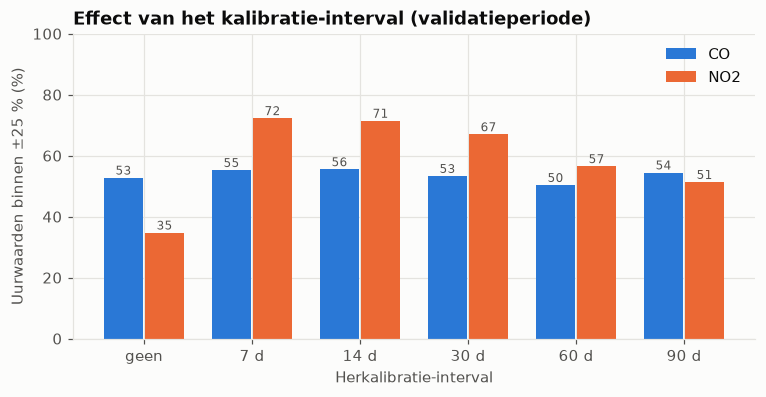

In [7]:
rijen = []
for s, c in SENSOREN.items():
    ref = df.loc[validatie, c["ref"]]
    for iv in [None, 7, 14, 30, 60, 90]:
        r = kal[s]["statisch"] if iv is None else kalibreer(df, s, MET_OMGEVING[s], iv)
        p = prestaties(ref, r[validatie])
        rijen.append({"sensor": s, "interval": "geen" if iv is None else f"{iv} d",
                      "binnen ±25 %": p["binnen_dqo"], "RMSE": p["rmse"], "bias": p["bias"]})
interval = pd.DataFrame(rijen)

fig, ax = plt.subplots(figsize=(8, 3.6))
labels = interval.interval.unique()
x = np.arange(len(labels))
for i, (s, kleur) in enumerate(zip(SENSOREN, [BLAUW, ORANJE])):
    w = interval[interval.sensor == s]["binnen ±25 %"].to_numpy() * 100
    ax.bar(x + (i - 0.5) * 0.38, w, width=0.36, color=kleur, label=s)
    for xi, wi in zip(x, w):
        ax.text(xi + (i - 0.5) * 0.38, wi + 1, f"{wi:.0f}", ha="center", fontsize=8, color=INKT2)
ax.set_xticks(x, labels)
ax.set_xlabel("Herkalibratie-interval")
ax.set_ylabel("Uurwaarden binnen ±25 % (%)")
ax.set_ylim(0, 100)
ax.set_title("Effect van het kalibratie-interval (validatieperiode)")
ax.legend(loc="upper right")
fig.savefig(FIG / "04_kalibratie_interval.png")
interval.pivot(index="interval", columns="sensor", values="binnen ±25 %").loc[labels]

**Bevinding.** Voor NO2 verdubbelt herkalibratie om de 7–14 dagen het aandeel bruikbare uurwaarden
(35 % → 71 %) en halveert de RMSE. Langer dan 30 dagen wachten kost duidelijk kwaliteit.
Voor CO verwijdert herkalibratie de bias, maar de spreiding blijft: daar is de beperking de ruis
van de sensor, niet de drift. **Advies: kalibratie-interval van 14 dagen**, als compromis tussen kwaliteit
en de kosten van co-locatie.

## 5. Onzekerheidsbudget volgens de GUM (JCGM 100:2008)

Voor één gekalibreerde uurwaarde (relatief, in ln-ruimte):

| Component | Type | Bron |
|---|---|---|
| Spreiding kalibratiemodel | A | standaardafwijking van de residuen |
| Modelparameters | A | covariantiematrix van de fit, bij gemiddelde condities |
| Referentie-analysator | B | aanname: U = 15 % (k = 2) volgens EN 14626 / EN 14211 |
| Drift binnen het interval | B | P95 van de 14-daagse bias, rechthoekige verdeling |
| Resolutie ruwe sensor | B | 1 telling, rechthoekige verdeling |

De componenten zijn ongecorreleerd en worden kwadratisch opgeteld: $u_c = \sqrt{\sum u_i^2}$, $U = k \cdot u_c$ met $k = 2$.

In [8]:
budgetten, samenvatting, mc = {}, [], {}
for s, c in SENSOREN.items():
    ref = df.loc[validatie, c["ref"]]
    drift = blokdrift(ref, kal[s]["herkalibratie"][validatie], HERKALIBRATIE_DAGEN).abs().quantile(0.95)
    model = fit(df.loc[:KALIBRATIE_EINDE], c["ref"], c["ruw"], MET_OMGEVING[s])
    budgetten[s] = onzekerheidsbudget(df, s, model, drift, HERKALIBRATIE_DAGEN)
    mc[s] = monte_carlo(budgetten[s])
    rel = relatieve_fout(ref, kal[s]["herkalibratie"][validatie])
    samenvatting.append({"sensor": s, **samenvatting_budget(budgetten[s]),
                         "MC 2,5 %": np.quantile(mc[s], 0.025),
                         "MC 97,5 %": np.quantile(mc[s], 0.975),
                         "empirisch P95 |fout|": rel.abs().quantile(0.95)})
pd.concat(budgetten.values()).set_index(["sensor", "component"])[["type", "verdeling", "u_rel", "aandeel"]]

type    verdeling  u_rel  aandeel
sensor component                                                             
CO     Spreiding kalibratiemodel (residuen)    A      normaal  0.243    0.563
       Onzekerheid modelparameters             A      normaal  0.008    0.001
       Referentie-analysator (EN-norm, k=2)    B      normaal  0.075    0.054
       Drift binnen 14-daags interval          B  rechthoekig  0.201    0.383
       Resolutie ruwe sensor (1 telling)       B  rechthoekig  0.001    0.000
NO2    Spreiding kalibratiemodel (residuen)    A      normaal  0.210    0.618
       Onzekerheid modelparameters             A      normaal  0.007    0.001
       Referentie-analysator (EN-norm, k=2)    B      normaal  0.075    0.079
       Drift binnen 14-daags interval          B  rechthoekig  0.147    0.302
       Resolutie ruwe sensor (1 telling)       B  rechthoekig  0.000    0.000

In [9]:
pd.DataFrame(samenvatting).set_index("sensor")

,u_c_rel,k,U_rel,voldoet_dqo,"MC 2,5 %","MC 97,5 %",empirisch P95 |fout|
sensor,,,,,,,
CO,0.324,2.000,0.649,False,-0.467,0.873,0.969
NO2,0.267,2.000,0.533,False,-0.405,0.680,0.608


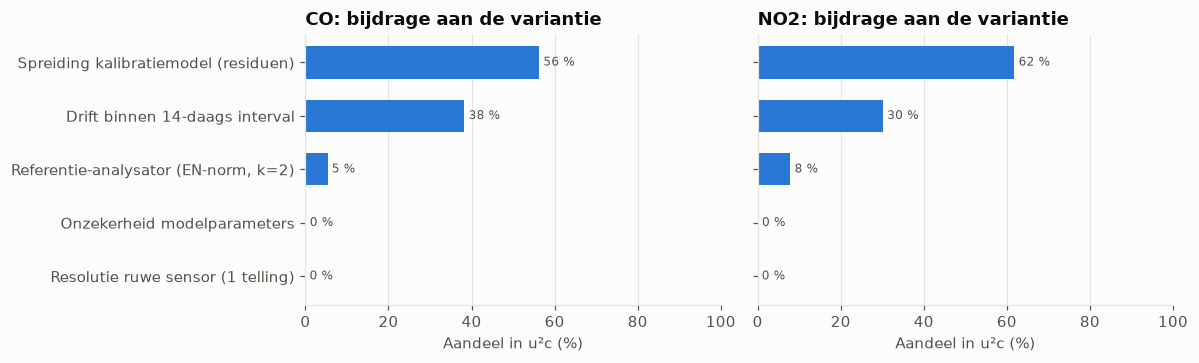

In [10]:
fig, assen = plt.subplots(1, 2, figsize=(11, 3.4), sharex=True)
for ax, (s, b) in zip(assen, budgetten.items()):
    b = b.sort_values("aandeel")
    ax.barh(b.component, b.aandeel * 100, color=BLAUW, height=0.6)
    for y, v in enumerate(b.aandeel * 100):
        ax.text(v + 1, y, f"{v:.0f} %", va="center", fontsize=8, color=INKT2)
    ax.set_title(f"{s}: bijdrage aan de variantie")
    ax.set_xlim(0, 100)
    ax.grid(axis="y", visible=False)
assen[0].set_xlabel("Aandeel in u²c (%)"); assen[1].set_xlabel("Aandeel in u²c (%)")
assen[1].set_yticklabels([])
fig.tight_layout()
fig.savefig(FIG / "05_onzekerheidsbudget.png");

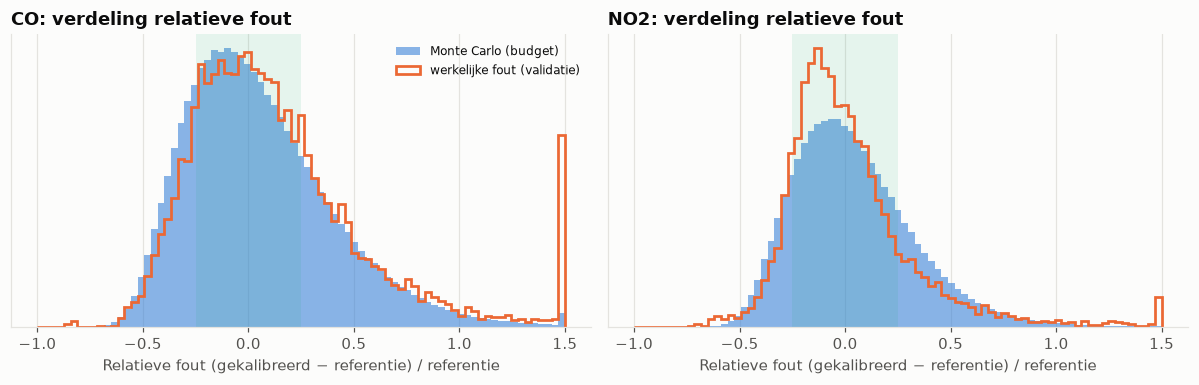

In [11]:
fig, assen = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, s in zip(assen, SENSOREN):
    ref = df.loc[validatie, SENSOREN[s]["ref"]]
    rel = relatieve_fout(ref, kal[s]["herkalibratie"][validatie])
    bins = np.linspace(-1, 1.5, 80)
    ax.hist(np.clip(mc[s], -1, 1.5), bins=bins, density=True, color=BLAUW, alpha=0.55,
            label="Monte Carlo (budget)")
    ax.hist(np.clip(rel, -1, 1.5), bins=bins, density=True, histtype="step", color=ORANJE,
            lw=1.8, label="werkelijke fout (validatie)")
    ax.axvspan(-0.25, 0.25, color=AQUA, alpha=0.10, lw=0)
    ax.set_title(f"{s}: verdeling relatieve fout")
    ax.set_xlabel("Relatieve fout (gekalibreerd − referentie) / referentie")
    ax.set_yticks([])
assen[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "06_monte_carlo.png");

**Bevinding.**

* De uitgebreide onzekerheid van één **uurwaarde** is ±65 % (CO) en ±53 % (NO2): ruim boven de 25 % DQO.
  Uurwaarden van deze sensoren zijn dus *niet* geschikt als indicatieve meting.
* De grootste bronnen zijn de **modelspreiding** (56–62 %) en de **drift** (30–38 %).
  De referentie en de resolutie spelen nauwelijks een rol, en precies daar winst zoeken heeft dus geen zin.
* De Monte Carlo-simulatie (JCGM 101) toont dat de verdeling **asymmetrisch** is (log-normaal):
  overschattingen zijn groter dan onderschattingen. Een symmetrisch ±U-interval volgens de GUM is hier
  een benadering.
* **Validatie van het budget:** voor NO2 ligt de werkelijke P95-fout (61 %) dicht bij het budget (55 %).
  Voor CO is de werkelijke fout groter (97 %), omdat bij lage concentraties (< 0,5 mg/m³) de
  relatieve fout explodeert. De onzekerheid is daar concentratie-afhankelijk; een relatief budget
  onderschat haar.

## 6. Middelen helpt: daggemiddelden

In [12]:
rijen = []
for s, c in SENSOREN.items():
    ref_u = df.loc[validatie, c["ref"]]
    gek_u = kal[s]["herkalibratie"][validatie]
    ok = ref_u.notna() & gek_u.notna()
    dag_ref = ref_u[ok].resample("D").mean()
    dag_gek = gek_u[ok].resample("D").mean()
    genoeg = ref_u[ok].resample("D").count() >= 18      # ≥ 75 % van de uren
    for niveau, r, g in [("uur", ref_u, gek_u), ("dag", dag_ref[genoeg], dag_gek[genoeg])]:
        rel = relatieve_fout(r, g)
        rijen.append({"sensor": s, "niveau": niveau, "n": len(rel),
                      "binnen ±25 %": (rel.abs() <= 0.25).mean(),
                      "P95 |fout|": rel.abs().quantile(0.95)})
pd.DataFrame(rijen).set_index(["sensor", "niveau"])

n  binnen ±25 %  P95 |fout|
sensor niveau                                
CO     uur     6384         0.555       0.969
       dag      258         0.651       0.525
NO2    uur     6445         0.714       0.608
       dag      268         0.896       0.382

**Bevinding.** Op daggemiddelden ligt 90 % van de NO2-dagen binnen ±25 %. Toepassingen zoals
trendanalyse, hotspot-detectie en het opvullen van ontbrekende referentiedata zijn dus wel realistisch.

## 7. Conclusies en aanbevelingen

1. **Kalibreer in log-ruimte**, per sensor gekozen: omgevingscorrectie voor NO2 wel, voor CO niet
   (die verslechtert de validatie door overfitting).
2. **Herkalibreer elke 14 dagen** via co-locatie. Voor NO2 verdubbelt dit het aandeel bruikbare data
   (35 % → 71 %).
3. **Uurwaarden halen de DQO niet** (U ≈ 53–65 %). Rapporteer daggemiddelden of gebruik de sensor voor trends.
4. **Wil je de onzekerheid omlaag, pak dan de modelspreiding en de drift aan**: een betere referentie heeft
   geen zin, want die levert < 8 % van de variantie.
5. **Valideer je onzekerheidsbudget empirisch.** Het relatieve budget klopt voor NO2, maar onderschat de fout
   van CO bij lage concentraties.

## 8. Export voor Power BI

In [13]:
import export_powerbi
tabellen = export_powerbi.main()

metingen                    18714 rijen
maandkwaliteit                 56 rijen
kalibratie_interval            12 rijen
onzekerheidsbudget             10 rijen
onzekerheid_samenvatting        2 rijen
sensoren                        2 rijen
